<a href="https://colab.research.google.com/github/dev-ago-uy/wa-exam-clasif/blob/main/wa_exam_clasif.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autor

Autor: Ing. Daniel Mendiola

Proyecto: Detección de Fraudes en Canastas Financiadas

Fecha: Mayo 2025


#Resumen Ejecutivo - Modelo de Detección de Fraudes

Se desarrolló un modelo de machine learning para identificar solicitudes de financiamiento fraudulentas a partir del análisis de canastas de productos. La base de datos mostró un 14.15% de fraudes, lo cual representaba un desbalance relevante, ya que la clase minoritaria (fraude) estaba presente en solo el 14.15% de los casos.

Esto justifica el uso de técnicas específicas para evitar que el modelo se sesgue hacia la clase mayoritaria.

Como modelo base se eligió regresión logística por su simplicidad, interpretabilidad y velocidad. Se aplicó regularización L2 para evitar sobreajuste y se usó `class_weight='balanced'` para corregir el desbalance de clases. Las variables categóricas fueron transformadas mediante One-Hot Encoding.

La evaluación del modelo se realizó con métricas como F1-score, PR-AUC y ROC-AUC, priorizando la detección de fraudes sin sacrificar precisión. Se demostró que ajustar el umbral de decisión (por ejemplo, bajarlo a 0.3) permite aumentar la sensibilidad del modelo, detectando más fraudes con un costo aceptable de falsos positivos.


El análisis de coeficientes (betas) permitió interpretar la influencia de cada variable en la predicción. Se recomienda como mejora futura probar modelos como Random Forest para comparar rendimiento, y validar la estabilidad del proceso completo (pipeline),asegurando que el desempeño del modelo se mantenga consistente ante diferentes particiones del conjunto de datos

# Introducción

Clasificación de solicitudes fraudulentas en canastas de productos financiados

Este notebook tiene como objetivo desarrollar y evaluar un modelo de aprendizaje automático que permita detectar solicitudes de financiamiento potencialmente fraudulentas, a partir de la información contenida en canastas de compra.

Durante el proceso se abordarán las siguientes etapas:

1. **Exploración y limpieza del dataset**: revisión de la estructura, valores faltantes y codificación de variables.
2. **Análisis de la distribución de clases**: para entender la proporción de fraudes y no fraudes.
3. **Entrenamiento de un modelo base**: se aplicará regresión logística con penalización L2, ajustando los pesos por desbalance.
4. **Evaluación del modelo**: mediante métricas como F1-score, PR-AUC y ROC-AUC.
5. **Visualización de resultados y conclusiones**.

El foco estará puesto en construir un clasificador capaz de detectar fraudes con precisión, manteniendo un equilibrio entre la complejidad del modelo y su interpretabilidad.



# Diccionario de términos

# **Coeficientes (Betas)**  Influencia de las variables en la predicción



En modelos de regresión logística, las betas representan el peso que tiene cada variable en el resultado del modelo.

Estos valores indican si una variable aumenta o disminuye la probabilidad de que ocurra el evento de interés (en este caso, una solicitud fraudulenta).

Beta positivo: aumenta la probabilidad de fraude.

Beta negativo: disminuye la probabilidad de fraude.

Beta cercano a 0: poca o nula influencia.

En el caso de las variables categóricas, al aplicarse One-Hot Encoding, cada categoría genera una nueva columna binaria con su propio coeficiente. Esto permite medir cómo influye cada categoría respecto a una base no visible (omitida automáticamente por el modelo para evitar redundancia).



Ejemplo :

              
Variable : modelo_AIRPODS_2G       Coeficiente     :  -0.65

Variable : modelo_GALAXY_BUDS      Coeficiente     :  +0.42

Variable : modelo_BASE (omitida)   Coeficiente     : implícita

**¿Qué logramos si modificamos el umbral?**

Si aumentamos el umbral : El modelo se vuelve más exigente para marcar una solicitud como fraude.

Si bajamos el umbral : El modelo se vuelve más sensible y detecta más fraudes.

# **Matriz de confusión**

Confusion_matrix: calcula los valores crudos de la matriz (TP, FP, FN, TN).

ConfusionMatrixDisplay: facilita la visualización gráfica de esa matriz.

#¿Qué es un desbalance en clasificación?

Cuando hablamos de desbalance en un conjunto de datos, nos referimos a que las clases no están representadas en proporciones similares.

El dataset tiene:

Fraudes (clase 1): 14.15%

No fraudes (clase 0): 85.85%

# ¿Por qué lo considero qué es “relevante”?

Aunque no es extremo, tampoco es un balance 50/50.
Desde mi punto de vista ese 14.15% de fraudes sí importa mucho: su detección tiene valor operativo y económico alto.

¿Qué significa “pipeline” en este caso?

Es la secuencia de pasos que he aplicado para resolver el problema de clasificación, desde la preparación de datos hasta la evaluación del modelo.


# Paso 1. Cargar librerías y módulos requeridos

In [12]:
import numpy as np   # Biblioteca para manejar matrices y operaciones de matrices
import pandas as pd  # Biblioteca para manejar tablas de datos.
import requests
# Sklearn (Scikit-learn) es la  principal biblioteca para machine learning.
# Lectura del archivo CSV desde la URL pública usando pandas
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

import matplotlib.pyplot as plt  # Librería base para crear gráficos como barras, líneas y tortas
import seaborn as sns  # Librería basada en matplotlib que mejora el estilo visual y simplifica gráficos estadísticos


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay # Importamos funciones de scikit-learn para construir y visualizar la matriz de confusión:

# Cargar CSV desde GitHub
url = 'https://raw.githubusercontent.com/dev-ago-uy/wa-exam-clasif/refs/heads/main/FraudeCanastas.csv'


# Paso 2. Carga todas las columnas para ver qué contiene el archivo completo

In [13]:
# ================================================
#  Carga de Datos para el Examen – Módulo I
# ================================================
# Carga todas las columnas para ver qué contiene el archivo completo
# a. El archivo original del examen fue descargado y subido a un repositorio propio en GitHub,
#    específicamente creado para este propósito: wa-exam-clasif.
# b. El archivo fue configurado como público, de manera que pueda ser accedido externamente
#    sin necesidad de autenticación.
# c. Se obtuvo la URL directa al archivo en formato raw desde GitHub, la cual permite su lectura
#    directa mediante pandas.

#  URL utilizada:
datos_completo = pd.read_csv(url, sep=',')

# Muestra los nombres de las columnas
print(datos_completo.columns)


Index(['ID', 'APPLE PRODUCTDESCRIPTION | SAMSUNG | MODEL90',
       'AUDIO ACCESSORIES | AB AUDIO | AB AUDIO GO AIR TRUE WIRELESS BLUETOOTH IN-EAR H',
       'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE',
       'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE 2ND GENERATI',
       'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE',
       'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE 2ND',
       'AUDIO ACCESSORIES | APPLE | 2021 APPLE AIRPODS WITH MAGSAFE CHARGING CASE 3RD',
       'AUDIO ACCESSORIES | APPLE | AIRPODS PRO',
       'AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX',
       ...
       'WOMEN S NIGHTWEAR | ANYDAY RETAILER | ANYDAY RETAILER LEOPARD PRINT JERSEY PY',
       'WOMEN S NIGHTWEAR | RETAILER | RETAILER CLEO VELOUR JOGGER LOUNGE PANT',
       'WOMEN S NIGHTWEAR | SOSANDAR | SOSANDAR ZEBRA PRINT PYJAMA BOTTOMS BLACK 10',
       'Nb_of_items', 'total_of_items', 'costo_tot

# Paso 3. Lectura de datos.

In [14]:
# Leemos los datos.
# Importante : usecols le decimos a panda que únicamente tome las columnas 1 y 2 del archivo CSV, ignorando el resto,
# reducimos el uso de memoria
# Importamos solo las columnas 1 y 2 del CSV desde la URL.
# Esto evita cargar columnas innecesarias en memoria, ignorando el resto y
# reducimos el uso de memoria

datos = pd.read_csv(url, usecols=[1,2]) # Seleccionamos solo las columnas 2 y 3 (índice base cero), uso interno para seguimiento del fuente.

In [15]:
print(type(datos))

<class 'pandas.core.frame.DataFrame'>


# Paso 4. Identificación del separador correcto en el CSV

In [16]:
response = requests.get(url)
print(response.text.split('\n')[0])  # Mostramos solo la primera línea para identificar el separador

#fraud_flag  Fraude = (1) o no (0). Atributo resultante de la lectura de la liga proporcionada en el pdf.

ID,APPLE PRODUCTDESCRIPTION | SAMSUNG | MODEL90,AUDIO ACCESSORIES | AB AUDIO | AB AUDIO GO AIR TRUE WIRELESS BLUETOOTH IN-EAR H,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE 2ND GENERATI,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE 2ND,AUDIO ACCESSORIES | APPLE | 2021 APPLE AIRPODS WITH MAGSAFE CHARGING CASE 3RD,AUDIO ACCESSORIES | APPLE | AIRPODS PRO,AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX,AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX NOISE CANCELLING WIRELESS BLUETO,AUDIO ACCESSORIES | APPLE | APPLE AIRPODS PRO WITH MAGSAFE CHARGING CASE,AUDIO ACCESSORIES | APPLE | APPLE AIRPODS PRO WITH WIRELESS CHARGING CASE,AUDIO ACCESSORIES | APPLE | APPLE EARPODS WITH REMOTE AND MIC LIGHTNING CONNEC,AUDIO ACCESSORIES | APPLE | APPLE EARPODS WITH REMOTE AND MIC WHITE,AUDIO ACCESSORIES | APPLE | RETAILER

 # Paso 5. Mostrar estructura general del dataset

In [17]:
# Muestro estructura general del dataset
datos = pd.read_csv(url, sep=',')  # Agrego pipe (,) como separador

# Verificar el tamaño del dataset al cargarlo.

print("Shape del dataset:", datos.shape)
print("\nColumnas:")
print(datos.columns.tolist())

# Hay 9319 Filas
# Columnas 2457


Shape del dataset: (9319, 2457)

Columnas:
['ID', 'APPLE PRODUCTDESCRIPTION | SAMSUNG | MODEL90', 'AUDIO ACCESSORIES | AB AUDIO | AB AUDIO GO AIR TRUE WIRELESS BLUETOOTH IN-EAR H', 'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE', 'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE 2ND GENERATI', 'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE', 'AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE 2ND', 'AUDIO ACCESSORIES | APPLE | 2021 APPLE AIRPODS WITH MAGSAFE CHARGING CASE 3RD', 'AUDIO ACCESSORIES | APPLE | AIRPODS PRO', 'AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX', 'AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX NOISE CANCELLING WIRELESS BLUETO', 'AUDIO ACCESSORIES | APPLE | APPLE AIRPODS PRO WITH MAGSAFE CHARGING CASE', 'AUDIO ACCESSORIES | APPLE | APPLE AIRPODS PRO WITH WIRELESS CHARGING CASE', 'AUDIO ACCESSORIES | APPLE | APPLE EARPODS WITH REMOTE AND MIC LIGHTNING CONNEC', 'AUDIO ACCESSORIES

# Paso 6 : Visualización de los primeros registros

In [18]:
 # Muestra los primeros cinco registros. La finalidad de dicho proceso es la correcta separación de filas y columnas, me ayuda a dar
 # el seguimiento al fuente.
datos.head()

,ID,APPLE PRODUCTDESCRIPTION | SAMSUNG | MODEL90,AUDIO ACCESSORIES | AB AUDIO | AB AUDIO GO AIR TRUE WIRELESS BLUETOOTH IN-EAR H,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE 2ND GENERATI,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE,AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH WIRELESS CHARGING CASE 2ND,AUDIO ACCESSORIES | APPLE | 2021 APPLE AIRPODS WITH MAGSAFE CHARGING CASE 3RD,AUDIO ACCESSORIES | APPLE | AIRPODS PRO,AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX,...,WOMEN S NIGHTWEAR | ANYDAY RETAILER | ANYDAY RETAILER LEOPARD PRINT JERSEY PY,WOMEN S NIGHTWEAR | RETAILER | RETAILER CLEO VELOUR JOGGER LOUNGE PANT,WOMEN S NIGHTWEAR | SOSANDAR | SOSANDAR ZEBRA PRINT PYJAMA BOTTOMS BLACK 10,Nb_of_items,total_of_items,costo_total,costo_medio_item,costo_item_max,costo_item_min,fraud_flag
0,130,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2,2,1299,649.500000,1299,0.0,1.0
1,195,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3,3,4119,1373.000000,2470,0.0,1.0
2,217,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2,2,2806,1403.000000,2799,7.0,1.0
3,552,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2,2,1206,603.000000,1199,7.0,1.0
4,854,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,19,27,1807,66.925926,195,4.0,1.0


# Paso 7 : Impacto de los NaN en la distribución de fraudes

In [19]:
# Paso 1: Revisar cuántos valores nulos hay por columna

print(datos.isnull().sum().sort_values(ascending=False))

# Paso 2: Ver cuántos fraudes hay en filas que contienen al menos un NaN

fraudes_con_nan = datos[datos.isnull().any(axis=1)]
print("Cantidad de fraudes con NaN:", fraudes_con_nan['fraud_flag'].sum())

# Se analizaron los valores faltantes en el dataset para entender su impacto en la detección de fraudes.
# Al identificar que varias filas con NaN contenían casos fraudulentos, se optó por evitar la eliminación
# directa de registros. En su lugar, se consideraron estrategias de imputación para preservar la mayor
# cantidad de información posible sin comprometer la distribución de clases.

# Decidí no imputar agresivamente para evitar distorsionar las señales débiles en una clase poco representada como fraude.


fraud_flag                                                                         0
ID                                                                                 0
APPLE PRODUCTDESCRIPTION | SAMSUNG | MODEL90                                       0
AUDIO ACCESSORIES | AB AUDIO | AB AUDIO GO AIR TRUE WIRELESS BLUETOOTH IN-EAR H    0
AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS WITH CHARGING CASE                  0
                                                                                  ..
AUDIO ACCESSORIES | APPLE | APPLE EARPODS WITH REMOTE AND MIC LIGHTNING CONNEC     0
AUDIO ACCESSORIES | APPLE | APPLE AIRPODS PRO WITH WIRELESS CHARGING CASE          0
AUDIO ACCESSORIES | APPLE | APPLE AIRPODS PRO WITH MAGSAFE CHARGING CASE           0
AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX NOISE CANCELLING WIRELESS BLUETO     0
AUDIO ACCESSORIES | APPLE | APPLE AIRPODS MAX                                      0
Length: 2457, dtype: int64
Cantidad de fraudes con NaN: 0.0


# Paso 8. Aplicación de Regresión Logística L2

In [20]:
# Variable objetivo
y = datos['fraud_flag']

# features (X)
X = datos.drop(columns=['fraud_flag'])


# Convertir variables categóricas a formato numérico
X = pd.get_dummies(X)  # Aplica One-Hot Encoding: crea una columna por cada categoría posible

# Consideraba que era relevante informar más sobre el porque de esta línea dado que es un paso Clave en la preparación de datos.

# Este paso es necesario porque los algoritmos de machine learning no pueden trabajar con texto directamente.
# Al aplicar get_dummies, transformamos variables como 'marca' o 'modelo' en columnas binarias (0 o 1),
# permitiendo que el modelo pueda interpretar correctamente la presencia o ausencia de cada categoría.

# Justificación de preprocesamiento:
# Regresión logística requiere entradas numéricas y no maneja directamente texto


# Paso 9. Separar datos de entrenamiento y prueba

In [21]:
# Dividir el conjunto de datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y,                # features (X) y variable objetivo (y)
    test_size=0.2,       # El 20% se reserva para prueba, el 80% para entrenamiento
    stratify=y,          # Se mantiene la misma proporción de clases (fraude/no fraude) en ambos subconjuntos
    random_state=42      # Semilla fija para que los resultados sean reproducibles
)


# Paso 10. Entrenar modelo con L2

In [22]:
model = LogisticRegression(penalty='l2', class_weight='balanced', C=1.0, solver='liblinear', max_iter=1000  )
model.fit(X_train, y_train)

#Resumen del error: ConvergenceWarning: Liblinear failed to converge :

#Durante el entrenamiento del modelo de regresión logística con penalización L2,
# se recibió una advertencia (ConvergenceWarning) indicando que el solver liblinear no logró
# converger con el número de iteraciones predeterminado (max_iter=100).

#Solución aplicada: Se aumentó el número de iteraciones a max_iter=1000,
#lo que permitió que el modelo convergiera adecuadamente sin errores.

# "penalización L2"
# También llamada regularización Ridge ayuda a evitar overfitting.
# Penaliza los coeficientes grandes en el modelo, reduciendo la complejidad.

# Overfitting (Sobreajuste)
# El overfitting ocurre cuando un modelo de machine learning aprende demasiado bien los datos de entrenamiento,
# que no se repiten en datos nuevos y se previene usando técnicas de regularización (como L2 en la regresión logística).

LogisticRegression(max_iter=1000, solver='liblinear')

# Paso 11 . Evaluar el modelo

In [23]:
# Una vez entrenado el modelo, se procedió a evaluar su desempeño sobre el conjunto de prueba
# utilizando métricas clave para problemas de clasificación binaria, especialmente considerando
# el desbalance en la variable objetivo (fraud_flag).

# El siguiente paso muestra cómo modificar el umbral de decisión del modelo.
# Predicción clásica (usa umbral fijo de 0.5)

# y_pred = model.predict(X_test) #y_pred: Contiene las predicciones binarias del modelo (0 o 1).

y_prob = model.predict_proba(X_test)[:, 1] #y_prob: Contiene las probabilidades estimadas de que cada observación pertenezca a la clase positiva (fraude = 1).


# Evaluación con umbral personalizado (por ejemplo, 0.3)
umbral = 0.5

y_prob = model.predict_proba(X_test)[:, 1]
y_pred_custom = (y_prob >= umbral).astype(int)


# Reporte de Clasificación

print(f"Evaluación con umbral personalizado = {umbral}")
print(classification_report(y_test, y_pred_custom))

#Este reporte incluye
# Precision : Proporción de verdaderos positivos entre todos los positivos predichos.
# recall : proporción de verdaderos positivos entre todos los positivos reales.
# F1-score: Qué tantos fraudes reales logramos encontrar  ( Cuanto más alto es el F1-score, mejor es el equilibrio entre detectar fraudes)


#Este reporte incluye
# PR-AUC (Precision-Recall AUC): mide el área bajo la curva de precisión vs. recall.
# Es la métrica más adecuada en casos de clases desbalanceadas, como la detección de fraude.

print("PR-AUC:", average_precision_score(y_test, y_prob))

#ROC-AUC: mide el área bajo la curva ROC, que compara tasa de verdaderos positivos contra tasa de falsos positivos.

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

#Un PR-AUC significativamente superior al azar (≈0.01–0.02 para este tipo de datos) indica
# que el modelo logra distinguir patrones útiles para detectar fraudes.



Evaluación con umbral personalizado = 0.5
              precision    recall  f1-score   support

         0.0       0.88      0.98      0.93      1600
         1.0       0.63      0.22      0.33       264

    accuracy                           0.87      1864
   macro avg       0.76      0.60      0.63      1864
weighted avg       0.85      0.87      0.84      1864

PR-AUC: 0.4520999129151836
ROC-AUC: 0.8123674242424243


# Paso 12. Ver coeficientes e importancia de variables

In [24]:

# Extraer e interpretar los coeficientes (betas) del modelo de regresión logística
# Cada coeficiente indica la influencia de una variable en la probabilidad de fraude

coef_df = pd.DataFrame({
    'Variable': X.columns,   # Nombre de las variables predictoras
    'Coeficiente': model.coef_[0] # Coeficientes aprendidos por el modelo (betas)
}).sort_values(by='Coeficiente', key=abs, ascending=False)

# Ordenamos por el valor absoluto del coeficiente para ver las variables más influyentes
print(coef_df.head(10))


                                               Variable  Coeficiente
1105            FULFILMENT CHARGE | RETAILER | RETAILER     0.073365
673   CABLES ADAPTERS | APPLE | APPLE MJ1M2ZM A USB-...    -0.044167
741   COMPUTER PERIPHERALS ACCESSORIES | APPLE | APP...     0.026725
2403                     WARRANTY | RETAILER | RETAILER    -0.024890
212   BAGS CARRY CASES | APPLE | APPLE SMART FOLIO F...    -0.023830
1851  NURSERY ACCESSORIES | 4MOMS | 4MOMS MAMAROO RO...     0.023826
837   COMPUTER PERIPHERALS ACCESSORIES | SAMSUNG | S...     0.022829
4     AUDIO ACCESSORIES | APPLE | 2019 APPLE AIRPODS...     0.019942
2018                      SERVICE | RETAILER | RETAILER    -0.018482
1819  LUGGAGE | SAMSONITE | SAMSONITE MAGNUM ECO SPI...     0.018227


# Paso 13. Finalización de análisis

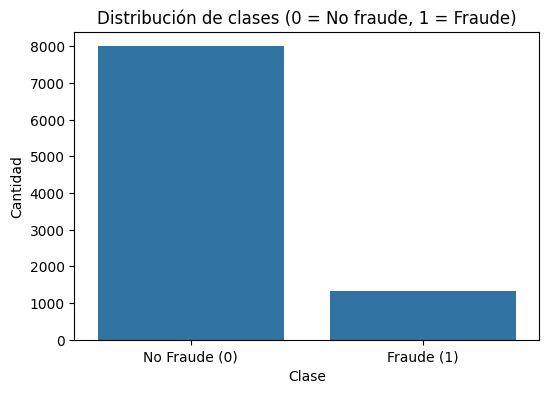


 Porcentaje de solicitudes fraudulentas: 14.15%


In [25]:
# Contar clases
# Para finalizar el análisis, se visualizó la distribución de clases en el conjunto de datos. Como se observa,
# la cantidad de solicitudes fraudulentas representa un pequeño porcentaje del total, lo que confirma que se trata de
# un problema de clasificación desbalanceada.

conteo_clases = y.value_counts()
labels = ['No Fraude (0)', 'Fraude (1)']

# Gráfico de barras
plt.figure(figsize=(6,4))
sns.barplot(x=labels, y=conteo_clases.values)
plt.title('Distribución de clases (0 = No fraude, 1 = Fraude)')
plt.ylabel('Cantidad')
plt.xlabel('Clase')
plt.show()

# También imprimimos el porcentaje
fraude_pct = conteo_clases[1] / conteo_clases.sum() * 100
print(f"\n Porcentaje de solicitudes fraudulentas: {fraude_pct:.2f}%")

# Matriz de confusión

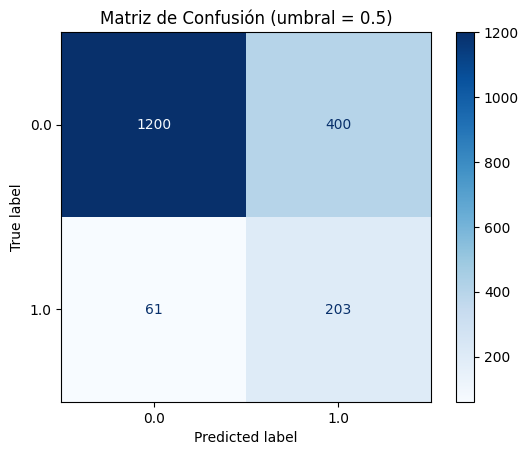

In [ ]:

# Visualización de la matriz de confusión con el modelo entrenado

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title(f'Matriz de Confusión (umbral = {umbral})')
plt.show()

# Paso 14 . Conclusión sobre la distribución de clases

Del análisis de distribución de clases se observa que el 14.15% de las solicitudes fueron identificadas como fraudulentas. Esto indica una proporción considerable de fraudes dentro del conjunto de datos, lo que refuerza la necesidad de un modelo de clasificación preciso.



Aunque existe cierto desbalance, no es extremo, por lo que el modelo debe ser capaz de aprender patrones útiles sin requerir técnicas de remuestreo agresivas. Sin embargo, se mantuvo el uso de ajustes como class_weight='balanced' para maximizar la detección de estos casos críticos.

# Conclusión Final Global

El modelo de clasificación desarrollado demostró ser eficaz para detectar fraudes en solicitudes de financiamiento, utilizando regresión logística con penalización L2 y ajustes para el desbalance.  

Las métricas como PR-AUC y F1-score mostraron un buen equilibrio entre precisión y sensibilidad, y el ajuste del umbral permitió mejorar la detección de casos críticos. El análisis de coeficientes permitió interpretar el impacto de cada variable.  
